# VGG16 


## 1. Imports


In [ ]:
import os, sys, json, glob, pickle, time, random, warnings, gc
import numpy as np
import pandas as pd
from itertools import combinations
from collections import Counter
from concurrent.futures import ProcessPoolExecutor, as_completed
from PIL import Image

from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix,
    mean_squared_error, mean_absolute_error, r2_score
)

import matplotlib.pyplot as plt
import seaborn as sns

try:
    from tqdm.auto import tqdm
except ImportError:
    def tqdm(it, **kwargs):
        return it

try:
    import tensorflow as tf
except ImportError:
    import subprocess
    subprocess.check_call([sys.executable, "-m", "pip", "install", "tensorflow", "--quiet"])
    import tensorflow as tf

from tensorflow.keras import layers, models, optimizers
from tensorflow.keras.applications import VGG16
from tensorflow.keras.applications.vgg16 import preprocess_input

warnings.filterwarnings("ignore")

SEED = 42
os.environ['PYTHONHASHSEED'] = str(SEED)

def set_global_seed(seed=SEED):

    random.seed(seed)
    np.random.seed(seed)
    try:
        tf.keras.utils.set_random_seed(seed)     
    except AttributeError:                        
        tf.random.set_seed(seed)

set_global_seed(SEED)

ENABLE_OP_DETERMINISM = False
if ENABLE_OP_DETERMINISM:
    tf.config.experimental.enable_op_determinism()

print("TensorFlow:", tf.__version__)
print("GPU available:", tf.config.list_physical_devices('GPU'))


TensorFlow: 2.20.0
GPU available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]


## 2. Configuration


In [ ]:
#  CONFIGURATION - VGG16 only pipeline (multi-task: classification + ADOS regression)
CKPT_DIR = '/kaggle/working' if os.path.isdir('/kaggle/working') else '.'
os.makedirs(CKPT_DIR, exist_ok=True)

IMG_SIZE = 224          # resolution of the saliency maps for VGG16
N_FOLDS = 5             # participant-level stratified K-fold cross-validation
USE_INNER_VAL = True    # True : early stopping / LR schedule use a validation split taken from the
                        #        TRAINING participants of each fold (no leakage from the test fold).
                        # False: original behaviour (the test fold itself is used as validation).
INNER_VAL_SIZE = 0.2    # share of the training participants used as inner validation
STD_DDOF = 1            # std of the metrics across folds: 1 = sample std, 0 = population std
FIT_VERBOSE = 2         # 2 = one line per epoch (keeps the log readable with 5 folds)
LAMBDA_ADOS = 0.3       # weight of the ADOS regression loss in the total loss
                        # (classification + LAMBDA_ADOS * regression), cf. Part B.2/B.3 of the paper

PHASE1_EPOCHS = 30      # warm-up (frozen VGG16 base)
PHASE2_EPOCHS = 15      # fine-tuning (unfreezes block5_conv3 only)
BATCH_SIZE = 8
PATIENCE_PHASE1 = 8
PATIENCE_PHASE2 = 6

VGG_CHUNKS_CKPT      = os.path.join(CKPT_DIR, 'ckpt_vgg_only_records_v2.pkl')
VGG_FOLD_CKPT_FMT    = os.path.join(CKPT_DIR, 'ckpt_vgg16_multitask_fold{}.keras')
VGG_CV_RESULTS_CKPT  = os.path.join(CKPT_DIR, 'ckpt_vgg16_cv_results.pkl')

N_WORKERS = max(1, min((os.cpu_count() or 2) - 1, 8))
print(f"CKPT_DIR = {CKPT_DIR}")
print(f"N_WORKERS = {N_WORKERS}")


CKPT_DIR = /kaggle/working
N_WORKERS = 3


## 3. Loading the DREAM dataset


In [ ]:
#  Loading the DREAM dataset

KAGGLE_INPUT = '/kaggle/input'

def find_dream_root(base):
    for root, dirs, files in os.walk(base):
        json_subdirs = [
            d for d in dirs
            if any(f.endswith('.json')
                   for f in os.listdir(os.path.join(root, d))
                   if os.path.isfile(os.path.join(root, d, f)))
        ]
        if json_subdirs:
            return root
    return None

if os.path.isdir(KAGGLE_INPUT):
    print("Environment detected: Kaggle")
    dream_root = find_dream_root(KAGGLE_INPUT)
    if dream_root is None:
        raise RuntimeError(
            "DREAM dataset not found in /kaggle/input/\n"
            "Check that it has been added to the notebook via 'Add Data'."
        )
    extract_path = dream_root
    print(f"DREAM dataset found at: {extract_path}")
else:
    print("Environment detected: Colab / local")
    from google.colab import drive
    drive.mount('/content/drive')

    dream_path   = '/content/drive/MyDrive/Master_TSA/Datasets/Dream dataset/snd1156-1-1.zip'
    extract_path = '/content/DREAM'
    os.makedirs(extract_path, exist_ok=True)

    import zipfile
    with zipfile.ZipFile(dream_path, 'r') as z:
        z.extractall(extract_path)
    print("Extraction complete at:", extract_path)

# Recursive search: does not assume how deep the participant folders are
SEARCH_ROOT = KAGGLE_INPUT if os.path.isdir(KAGGLE_INPUT) else extract_path
all_json_files = []
for root_, dirs_, files_ in os.walk(SEARCH_ROOT):
    dirs_.sort()
    for fname in sorted(files_):
        if fname.endswith(".json"):
            all_json_files.append(os.path.join(root_, fname))

print(f"JSON files detected: {len(all_json_files)}")


Environment detected: Kaggle
DREAM dataset found at: /kaggle/input/datasets/rymjaballah/dream-dataset/snd1156-1-1/data
JSON files detected: 3123


## 4. Utility functions (labels, viewframes, saliency KDE)


In [ ]:
#  Utility functions - labels, arrays, viewframes, saliency KDE

def safe_first(obj):
    if isinstance(obj, list):
        return obj[0] if obj else {}
    return obj if obj is not None else {}

def to_float_array(lst):
    if not lst:
        return np.empty(0, dtype=float)
    return pd.to_numeric(pd.Series(lst), errors='coerce').to_numpy(dtype=float)

def build_xyz_array(d, keys):
    cols = [to_float_array(d.get(k, [])) for k in keys]
    n = max((len(c) for c in cols), default=0)
    if n == 0:
        return None
    out = np.full((n, len(keys)), np.nan)
    for i, c in enumerate(cols):
        out[:len(c), i] = c
    return out

def assign_label(module, comm, inter):
    try:
        module = int(module)
    except (TypeError, ValueError):
        module = 1
    total = (comm or 0) + (inter or 0)
    cutoffs = {1: (7, 12), 2: (8, 12), 3: (7, 10)}
    asd_cut, aut_cut = cutoffs.get(module, (7, 12))
    if total >= aut_cut:
        return 'Autistic Disorder'
    elif total >= asd_cut:
        return 'ASD (AS, PDD)'
    return None

#Viewframes
VIEWFRAMES = {
    'front':  {'center': np.array([0.0, 0.0, 700.0]),
               'width_axis': np.array([1.0, 0.0, 0.0]), 'height_axis': np.array([0.0, 1.0, 0.0]),
               'width': 800.0, 'height': 600.0},
    'left':   {'center': np.array([-450.0, 0.0, 0.0]),
               'width_axis': np.array([0.0, 0.0, 1.0]), 'height_axis': np.array([0.0, 1.0, 0.0]),
               'width': 600.0, 'height': 600.0},
    'right':  {'center': np.array([450.0, 0.0, 0.0]),
               'width_axis': np.array([0.0, 0.0, 1.0]), 'height_axis': np.array([0.0, 1.0, 0.0]),
               'width': 600.0, 'height': 600.0},
    'top':    {'center': np.array([0.0, 450.0, 0.0]),
               'width_axis': np.array([1.0, 0.0, 0.0]), 'height_axis': np.array([0.0, 0.0, 1.0]),
               'width': 800.0, 'height': 600.0},
    'bottom': {'center': np.array([0.0, -300.0, 0.0]),
               'width_axis': np.array([1.0, 0.0, 0.0]), 'height_axis': np.array([0.0, 0.0, 1.0]),
               'width': 800.0, 'height': 600.0},
}

def ray_plane_intersection(Pv, D, vf):
    width_axis, height_axis = vf['width_axis'], vf['height_axis']
    width, height, center = vf['width'], vf['height'], vf['center']

    corner = center - (width / 2.0) * width_axis - (height / 2.0) * height_axis
    E1 = width_axis * width
    E2 = height_axis * height
    N = np.cross(E1, E2)
    N = N / np.linalg.norm(N)

    denom = D @ N
    if abs(denom) < 1e-9:
        return None
    t = ((corner - Pv) @ N) / denom
    if t <= 0:
        return None

    Pi = Pv + t * D
    rel = Pi - corner
    u_proj = rel @ width_axis
    v_proj = rel @ height_axis

    if 0.0 <= u_proj <= width and 0.0 <= v_proj <= height:
        return (u_proj - width / 2.0, v_proj - height / 2.0)
    return None

def assign_viewframe(Pv, D):
    for name in ['front', 'left', 'right', 'top', 'bottom']:
        res = ray_plane_intersection(Pv, D, VIEWFRAMES[name])
        if res is not None:
            return name, res[0], res[1]
    return None, None, None

#Saliency maps via KDE 
def compute_bandwidth(pts):
    n = len(pts)
    mean = pts.mean(axis=0)
    d = np.linalg.norm(pts - mean, axis=1)
    SD = np.sqrt(np.mean(d ** 2))
    Dm = np.median(d)
    SB = 0.9 * min(SD, np.sqrt(1.0 / np.log(2)) * Dm) * (n ** (-0.2))
    return max(SB, 1e-3)

def gaussian_kernel_2d(x):
    return (1.0 / (2.0 * np.pi)) * np.exp(-0.5 * np.sum(x ** 2, axis=-1))

def render_saliency_panel(points, half_u, half_v, grid_size=128):
    if len(points) < 5:
        return None
    pts = np.array(points)
    h = compute_bandwidth(pts)
    n = len(pts)
    uu, vv = np.meshgrid(
        np.linspace(-half_u, half_u, grid_size),
        np.linspace(-half_v, half_v, grid_size)
    )
    grid = np.stack([uu.ravel(), vv.ravel()], axis=-1)
    diffs = (grid[:, None, :] - pts[None, :, :]) / h
    kernel_vals = gaussian_kernel_2d(diffs)
    density = kernel_vals.sum(axis=1) / (n * h ** 2)
    density = density.reshape(grid_size, grid_size)
    density = (density - density.min()) / (density.max() - density.min() + 1e-9)
    return density

def build_multichannel_saliency_image(points_by_vf, img_size=IMG_SIZE, grid_size=128):
    def panel_or_zeros(name):
        p = render_saliency_panel(points_by_vf[name],
                                   VIEWFRAMES[name]['width'] / 2.0,
                                   VIEWFRAMES[name]['height'] / 2.0,
                                   grid_size=grid_size)
        return p if p is not None else np.zeros((grid_size, grid_size))

    front = panel_or_zeros('front')
    left, right = panel_or_zeros('left'), panel_or_zeros('right')
    top, bottom = panel_or_zeros('top'), panel_or_zeros('bottom')

    R = front
    G = (left + right) / 2.0
    B = (top + bottom) / 2.0

    rgb = np.stack([R, G, B], axis=-1)
    rgb_img = (rgb * 255).astype(np.uint8)
    rgb_img = np.array(Image.fromarray(rgb_img).resize((img_size, img_size)))
    return rgb_img

#Robust readers for the DREAM json files 
ID_KEYS = ('id', 'child_id', 'participant_id', 'childId', 'ID', 'subject_id')

def to_num(v):
    """ADOS value -> float or None (handles numbers, strings, lists and {'preTest': ..} dicts)."""
    if isinstance(v, dict):
        for k in ('preTest', 'pretest', 'pre_test', 'PreTest', 'value', 'score'):
            if k in v:
                return to_num(v[k])
        return None
    if isinstance(v, (list, tuple)):
        return to_num(v[0]) if v else None
    try:
        x = float(v)
        return None if np.isnan(x) else x
    except (TypeError, ValueError):
        return None

def deep_find_dict(obj, required, max_depth=4):
    queue = [(obj, 0)]
    while queue:
        cur, depth = queue.pop(0)
        if isinstance(cur, dict):
            if all(k in cur for k in required):
                return cur
            if depth < max_depth:
                queue += [(v, depth + 1) for v in cur.values() if isinstance(v, (dict, list))]
        elif isinstance(cur, list) and depth < max_depth:
            queue += [(v, depth + 1) for v in cur[:5] if isinstance(v, (dict, list))]
    return {}

def find_participant(data):
    for k in ('participant', 'child', 'subject'):
        if k in data:
            p = safe_first(data[k])
            if isinstance(p, dict):
                return p
    return {}

def find_ados(data):
    ados = data.get('ados', data.get('ADOS', {}))
    if isinstance(ados, dict):
        for k in ('preTest', 'pretest', 'pre_test', 'PreTest'):
            if isinstance(ados.get(k), dict):
                return ados[k]
        if 'communication' in ados:
            return ados
    return deep_find_dict(data, ('communication', 'interaction'))

def get_participant_id(p, data, fpath):
    """Participant id as a string: json id keys -> top-level keys -> parent folder name."""
    pid = None
    for k in ID_KEYS:
        v = p.get(k) if isinstance(p, dict) else None
        if v is not None and str(v).strip() not in ('', 'nan', 'None'):
            pid = v
            break
    if pid is None:
        for k in ID_KEYS:
            if data.get(k) is not None:
                pid = data[k]
                break
    if pid is None:
        pid = os.path.basename(os.path.dirname(fpath))
    return str(pid)

print("Utility functions loaded (labels, viewframes, saliency KDE).")


Utility functions loaded (labels, viewframes, saliency KDE).


## 5. Extracting saliency maps (1 image per session) + label + ADOS score


In [ ]:
#  Extraction: 1 aggregated saliency map (RGB image IMG_SIZE x IMG_SIZE) per
#  session, with ASD/Autistic label + continuous ADOS score + participant_id.
#  Everything is recomputed directly from the JSON files.

def process_json_file_vgg(fpath):
    with open(fpath) as f:
        data = json.load(f)

    p = find_participant(data)
    ados_data = find_ados(data)
    comm   = to_num(ados_data.get('communication'))
    inter  = to_num(ados_data.get('interaction'))
    module = to_num(ados_data.get('module'))
    label = assign_label(module, comm, inter)
    if label is None:
        return None

    pid = get_participant_id(p, data, fpath)
    ados_score = (comm or 0) + (inter or 0)

    skel = data.get('skeleton', {})
    eg   = data.get('eye_gaze', {})

    head_arr = build_xyz_array(skel.get('head', {}), ('x', 'y', 'z'))
    eye_arr  = build_xyz_array(eg, ('rx', 'ry', 'rz'))
    if head_arr is None or eye_arr is None:
        return None

    n = min(len(head_arr), len(eye_arr))
    if n == 0:
        return None
    head_arr, eye_arr = head_arr[:n], eye_arr[:n]

    valid = ~np.isnan(head_arr).any(axis=1) & ~np.isnan(eye_arr).any(axis=1)
    head_v, eye_v = head_arr[valid], eye_arr[valid]
    if len(head_v) < 5:
        return None

    points_by_vf = {name: [] for name in VIEWFRAMES}
    for Pv, D_raw in zip(head_v, eye_v):
        norm = np.linalg.norm(D_raw)
        if norm < 1e-9:
            continue
        D = D_raw / norm
        name, u, v = assign_viewframe(Pv, D)
        if name is not None:
            points_by_vf[name].append((u, v))

    img = build_multichannel_saliency_image(points_by_vf, img_size=IMG_SIZE)

    return {
        'participant_id': pid,
        'label': label,
        'ados_score': float(ados_score),
        'image': img,
        'file': fpath,
    }

MIN_PARTICIPANTS_IN_CKPT = 20
vgg_records = None
if os.path.exists(VGG_CHUNKS_CKPT):
    with open(VGG_CHUNKS_CKPT, 'rb') as f:
        _recs = pickle.load(f)
    if len({r['participant_id'] for r in _recs}) >= MIN_PARTICIPANTS_IN_CKPT:
        vgg_records = _recs
        print(f"Checkpoint found -> {len(vgg_records)} sessions loaded.")
    else:
        print("Checkpoint holds too few participants -> ignored, extraction restarts.")

if vgg_records is None:
    vgg_records, vgg_errors = [], []
    with ProcessPoolExecutor(max_workers=N_WORKERS) as ex:
        futures = {ex.submit(process_json_file_vgg, fp): fp for fp in all_json_files}
        for fut in tqdm(as_completed(futures), total=len(futures), desc="Extracting saliency maps"):
            try:
                res = fut.result()
            except Exception as e:                       # one bad file must not kill the run
                vgg_errors.append((futures[fut], repr(e)))
                continue
            if res is not None:
                vgg_records.append(res)
    
    vgg_records.sort(key=lambda r: r['file'])
    with open(VGG_CHUNKS_CKPT, 'wb') as f:
        pickle.dump(vgg_records, f)
    print(f"Checkpoint saved -> {VGG_CHUNKS_CKPT}")
    print(f"Files with errors: {len(vgg_errors)}", vgg_errors[:3] if vgg_errors else "")

print(f"JSON files: {len(all_json_files)} | valid sessions: {len(vgg_records)}")

sal_imgs   = np.stack([r['image'] for r in vgg_records])
sal_labels = np.array([r['label'] for r in vgg_records])
sal_ados   = np.array([r['ados_score'] for r in vgg_records], dtype=np.float32)
sal_pids   = np.array([str(r['participant_id']) for r in vgg_records])

n_participants_total = len(set(sal_pids.tolist()))
print(f"Unique participants: {n_participants_total}   (expected ~61)")
assert n_participants_total >= 2 * N_FOLDS, (
    f"Only {n_participants_total} participant(s) extracted: check dataset path / json structure "
    f"(json files found: {len(all_json_files)}).")

print(f"sal_imgs  : {sal_imgs.shape}")
print(f"Label distribution: {pd.Series(sal_labels).value_counts().to_dict()}")
print(f"ADOS score: min={sal_ados.min():.1f}  max={sal_ados.max():.1f}  mean={sal_ados.mean():.2f}")

Extracting saliency maps:   0%|          | 0/3123 [00:00<?, ?it/s]

Checkpoint saved -> /kaggle/working/ckpt_vgg_only_records_v2.pkl
Files with errors: 0 
JSON files: 3123 | valid sessions: 3038
Unique participants: 61   (expected ~61)
sal_imgs  : (3038, 224, 224, 3)
Label distribution: {'Autistic Disorder': 2382, 'ASD (AS, PDD)': 656}
ADOS score: min=7.0  max=20.0  mean=13.97


## 6. Label encoding + participant-level stratified 5-fold split (seed = 42)

In [ ]:
#  Label encoding + PARTICIPANT-LEVEL stratified K-fold (K = N_FOLDS, seed = SEED)
#  no participant is ever in the train and test part of the same fold,
#     and every participant is tested exactly once.
#  (VGG16 preprocess_input is applied per fold, see the CV loop.)
le = LabelEncoder()
y_sal_enc_all = le.fit_transform(sal_labels)
print(f"Classes: {dict(zip(le.classes_, le.transform(le.classes_)))}")

# One label / one ADOS score per participant (majority label, mean ADOS if several sessions)
df_pid = pd.DataFrame({'participant_id': sal_pids, 'label': sal_labels, 'ados_score': sal_ados})
pid_label = df_pid.groupby('participant_id')['label'].agg(lambda s: s.value_counts().idxmax())
ados_true_by_pid = df_pid.groupby('participant_id')['ados_score'].mean().to_dict()

unique_pids   = pid_label.index.values
unique_labels = pid_label.values
print(f"Participants: {len(unique_pids)} | per class: {pd.Series(unique_labels).value_counts().to_dict()}")

skf = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
folds = []
for k, (tr, te) in enumerate(skf.split(unique_pids, unique_labels), start=1):
    folds.append({'fold': k, 'train_pids': unique_pids[tr], 'test_pids': unique_pids[te]})
    print(f"Fold {k}: train={len(tr)} participants | test={len(te)} participants "
          f"| test classes: {pd.Series(unique_labels[te]).value_counts().to_dict()}")

_all_test = np.concatenate([f['test_pids'] for f in folds])
assert len(_all_test) == len(set(_all_test)) == len(unique_pids), "each participant must be tested exactly once"

Classes: {np.str_('ASD (AS, PDD)'): np.int64(0), np.str_('Autistic Disorder'): np.int64(1)}
Participants: 61 | per class: {'Autistic Disorder': 48, 'ASD (AS, PDD)': 13}
Fold 1: train=48 participants | test=13 participants | test classes: {'Autistic Disorder': 10, 'ASD (AS, PDD)': 3}
Fold 2: train=49 participants | test=12 participants | test classes: {'Autistic Disorder': 10, 'ASD (AS, PDD)': 2}
Fold 3: train=49 participants | test=12 participants | test classes: {'Autistic Disorder': 10, 'ASD (AS, PDD)': 2}
Fold 4: train=49 participants | test=12 participants | test classes: {'Autistic Disorder': 9, 'ASD (AS, PDD)': 3}
Fold 5: train=49 participants | test=12 participants | test classes: {'Autistic Disorder': 9, 'ASD (AS, PDD)': 3}


## 7. Training callbacks + participant-level evaluation functions


In [ ]:
#  Training callbacks + participant-level evaluation functions

def compute_boosted_class_weight(y_train, boost_minority=1.5):
    counts = pd.Series(y_train).value_counts().to_dict()
    n_tot = len(y_train)
    minority_class = min(counts, key=counts.get)
    weights = {c: n_tot / (len(counts) * n) for c, n in counts.items()}
    weights[minority_class] *= boost_minority
    return weights

class EveryNEpochLogger(tf.keras.callbacks.Callback):
    """Prints a loss summary every `every_n` epochs."""
    def __init__(self, every_n=5):
        super().__init__()
        self.every_n = every_n

    def on_epoch_end(self, epoch, logs=None):
        logs = logs or {}
        if (epoch + 1) % self.every_n == 0 or epoch == 0:
            parts = [f"epoch {epoch + 1:>4}"]
            for k, v in logs.items():
                parts.append(f"{k}={v:.4f}")
            print("  [every-5-epochs] " + " | ".join(parts))

class F1EarlyStoppingMultiOutput(tf.keras.callbacks.Callback):
    """Monitors the macro F1 of the classification output (output_index=0),
    and restores the weights of the best epoch based on this criterion rather
    than the global val_loss (which mixes classification + ADOS regression)."""
    def __init__(self, X_val, y_val_clf, patience=8, output_index=0):
        super().__init__()
        self.X_val = X_val
        self.y_val_clf = y_val_clf
        self.patience = patience
        self.output_index = output_index
        self.best_f1 = -1
        self.wait = 0
        self.best_weights = None

    def on_epoch_end(self, epoch, logs=None):
        preds = self.model.predict(self.X_val, verbose=0)
        clf_probs = preds[self.output_index]
        y_pred = np.argmax(clf_probs, axis=1)
        f1 = f1_score(self.y_val_clf, y_pred, average="macro")
        print(f"  [F1-macro val] epoch {epoch+1} : {f1:.4f}")
        if f1 > self.best_f1:
            self.best_f1 = f1
            self.wait = 0
            self.best_weights = self.model.get_weights()
        else:
            self.wait += 1
            if self.wait >= self.patience:
                print(f"  Early stop (F1) at epoch {epoch+1}, best F1={self.best_f1:.4f}")
                self.model.stop_training = True
                self.model.set_weights(self.best_weights)

    def on_train_end(self, logs=None):
        if self.best_weights is not None:
            self.model.set_weights(self.best_weights)


def evaluate_clf_at_participant_level(probs, y_true_seg, pids_seg, pid_set, label_names):
    """Aggregates classification probabilities per participant (softmax mean)
    then computes metrics on these aggregated predictions."""
    prob_by_pid, true_by_pid = {}, {}
    for pid in pid_set:
        m = np.array(pids_seg) == pid
        if m.sum() == 0:
            continue
        prob_by_pid[pid] = probs[m].mean(axis=0)
        true_by_pid[pid] = Counter(y_true_seg[m]).most_common(1)[0][0]

    pids_sorted = sorted(prob_by_pid.keys())
    y_true_p = np.array([true_by_pid[pid] for pid in pids_sorted])
    y_pred_p = np.array([int(np.argmax(prob_by_pid[pid])) for pid in pids_sorted])

    metrics = {
        'precision': precision_score(y_true_p, y_pred_p, average="macro", zero_division=0) * 100,
        'recall':    recall_score(y_true_p, y_pred_p, average="macro", zero_division=0) * 100,
        'f1':        f1_score(y_true_p, y_pred_p, average="macro", zero_division=0) * 100,
        'accuracy':  accuracy_score(y_true_p, y_pred_p) * 100,
        'n_participants': len(pids_sorted),
    }
    cm = confusion_matrix(y_true_p, y_pred_p)
    return metrics, cm, y_true_p, y_pred_p, pids_sorted


def get_participant_level_probs(probs, pids_seg, pid_set):
    prob_by_pid = {}
    for pid in pid_set:
        m = np.array(pids_seg) == pid
        if m.sum() == 0:
            continue
        prob_by_pid[pid] = probs[m].mean(axis=0)
    pids_sorted = sorted(prob_by_pid.keys())
    y_prob_p = np.stack([prob_by_pid[pid] for pid in pids_sorted])
    return y_prob_p, pids_sorted


def aggregate_ados_at_participant_level(ados_pred_seg, pids_seg, pid_set, ados_true_by_pid):

    pred_by_pid = {}
    for pid in pid_set:
        m = np.array(pids_seg) == pid
        if m.sum() == 0:
            continue
        pred_by_pid[pid] = float(np.mean(ados_pred_seg[m]))
    pids_sorted = sorted(pred_by_pid.keys())
    y_pred_p = np.array([pred_by_pid[pid] for pid in pids_sorted])
    y_true_p = np.array([ados_true_by_pid[pid] for pid in pids_sorted])
    return y_true_p, y_pred_p, pids_sorted

print("Callbacks and participant-level evaluation functions loaded.")


Callbacks and participant-level evaluation functions loaded.


## 8. Multi-task VGG16 model (classification + ADOS regression)

In [ ]:
def build_vgg16_multitask(n_classes):
    base_model = VGG16(weights='imagenet', include_top=False, input_shape=(IMG_SIZE, IMG_SIZE, 3))
    base_model.trainable = False
    x = layers.GlobalAveragePooling2D()(base_model.output)
    x = layers.Dense(256, activation='relu')(x)
    x = layers.Dropout(0.5)(x)
    class_output = layers.Dense(n_classes, activation='softmax', name='class_output')(x)
    reg_output   = layers.Dense(1, activation='linear', name='reg_output')(x)
    model = models.Model(base_model.input, [class_output, reg_output], name='vgg16_multitask')
    return model, base_model


def merge_histories(h1, h2):
    merged = {}
    for key in h1.history:
        merged[key] = h1.history[key] + h2.history.get(key, [])
    class FakeHistory:
        pass
    fake = FakeHistory()
    fake.history = merged
    return fake


def align_histories(h1, h2):
  
    out = {}
    for key in h1:
        a = list(h1[key]) + [np.nan] * (PHASE1_EPOCHS - len(h1[key]))
        out[key] = a + list(h2.get(key, []))
    return out


def train_vgg_fold(X_fit, y_clf_fit, y_ados_fit, X_val, y_clf_val, y_ados_val):
  
    tf.keras.backend.clear_session()
    set_global_seed(SEED)                       # same seed at the start of every fold

    model, base_model = build_vgg16_multitask(len(le.classes_))

    class_weight_vgg = compute_boosted_class_weight(y_clf_fit, boost_minority=1.5)
    sw_clf = np.array([class_weight_vgg[c] for c in y_clf_fit], dtype='float32')
    sw_reg = np.ones_like(sw_clf)  # no weighting for the regression head

    #Lists ordered like the model's outputs: [class_output, reg_output] 
    y_fit_list = [y_clf_fit, y_ados_fit]
    y_val_list = [y_clf_val, y_ados_val]
    sw_list    = [sw_clf, sw_reg]

    # Phase 1: warm-up, frozen VGG16 base
    model.compile(
        optimizer=optimizers.Adam(learning_rate=3e-5, clipnorm=1.0),
        loss=['sparse_categorical_crossentropy', 'mse'],
        loss_weights=[1.0, LAMBDA_ADOS],
        metrics=[['accuracy'], ['mae']]
    )
    f1_cb = F1EarlyStoppingMultiOutput(X_val, y_clf_val, patience=PATIENCE_PHASE1, output_index=0)
    reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=4, min_lr=1e-6)
    h1 = model.fit(
        X_fit, y_fit_list, sample_weight=sw_list, validation_data=(X_val, y_val_list),
        epochs=PHASE1_EPOCHS, batch_size=BATCH_SIZE,
        callbacks=[f1_cb, reduce_lr, EveryNEpochLogger(every_n=5)], verbose=FIT_VERBOSE
    )

    #Phase 2: light fine-tuning (a single conv layer unfrozen)
    base_model.trainable = True
    for layer in base_model.layers:
        layer.trainable = (layer.name == 'block5_conv3')
    model.compile(
        optimizer=optimizers.Adam(learning_rate=1e-5, clipnorm=1.0),
        loss=['sparse_categorical_crossentropy', 'mse'],
        loss_weights=[1.0, LAMBDA_ADOS],
        metrics=[['accuracy'], ['mae']]
    )
    f1_cb2 = F1EarlyStoppingMultiOutput(X_val, y_clf_val, patience=PATIENCE_PHASE2, output_index=0)
    h2 = model.fit(
        X_fit, y_fit_list, sample_weight=sw_list, validation_data=(X_val, y_val_list),
        epochs=PHASE2_EPOCHS, batch_size=BATCH_SIZE,
        callbacks=[f1_cb2, EveryNEpochLogger(every_n=5)], verbose=FIT_VERBOSE
    )

    merged = merge_histories(h1, h2).history
    aligned = align_histories(h1.history, h2.history)
    return model, merged, aligned

print("Model builder and per-fold 2-phase training function defined.")

Model builder and per-fold 2-phase training function defined.


## 8b. 5-fold cross-validation loop 

In [ ]:
CV_SIGNATURE = dict(SEED=SEED, N_FOLDS=N_FOLDS, PHASE1_EPOCHS=PHASE1_EPOCHS, PHASE2_EPOCHS=PHASE2_EPOCHS,
                    BATCH_SIZE=BATCH_SIZE, PATIENCE_PHASE1=PATIENCE_PHASE1, PATIENCE_PHASE2=PATIENCE_PHASE2,
                    LAMBDA_ADOS=LAMBDA_ADOS, USE_INNER_VAL=USE_INNER_VAL, INNER_VAL_SIZE=INNER_VAL_SIZE,
                    IMG_SIZE=IMG_SIZE, n_sessions=int(len(sal_imgs)), n_participants=int(len(unique_pids)))

cv_results = {}
if os.path.exists(VGG_CV_RESULTS_CKPT):
    with open(VGG_CV_RESULTS_CKPT, 'rb') as f:
        _ck = pickle.load(f)
    if _ck.get('signature') == CV_SIGNATURE:
        cv_results = _ck['results']
        print(f"CV checkpoint found -> folds already done: {sorted(cv_results)}")
    else:
        print("CV checkpoint was made with another configuration -> ignored (all folds retrained).")


def evaluate_fold(model, X_te, y_clf_te, y_ados_te, pids_te, te_pid_set):
    """Every metric of the original evaluation cell, for one fold."""
    y_prob, y_ados_pred = model.predict(X_te, verbose=0, batch_size=BATCH_SIZE)
    y_ados_pred = np.asarray(y_ados_pred).ravel()

    #classification
    m, _, y_true_p, y_pred_p, pids_sorted = evaluate_clf_at_participant_level(
        y_prob, y_clf_te, pids_te, te_pid_set, le.classes_)
    y_prob_p, _ = get_participant_level_probs(y_prob, pids_te, te_pid_set)
    try:
        if len(le.classes_) == 2:
            auc = roc_auc_score(y_true_p, y_prob_p[:, 1])
        else:
            auc = roc_auc_score(y_true_p, y_prob_p, multi_class="ovr", average="micro")
    except ValueError:
        auc = np.nan
    cm = confusion_matrix(y_true_p, y_pred_p, labels=np.arange(len(le.classes_)))

    #ADOS regression: session level
    mae_s  = mean_absolute_error(y_ados_te, y_ados_pred)
    mse_s  = mean_squared_error(y_ados_te, y_ados_pred)
    r2_s   = r2_score(y_ados_te, y_ados_pred)

    #ADOS regression: aggregated participant level
    y_ados_true_p, y_ados_pred_p, _ = aggregate_ados_at_participant_level(
        y_ados_pred, pids_te, te_pid_set, ados_true_by_pid)
    mae_p  = mean_absolute_error(y_ados_true_p, y_ados_pred_p)
    mse_p  = mean_squared_error(y_ados_true_p, y_ados_pred_p)
    r2_p   = r2_score(y_ados_true_p, y_ados_pred_p)

    metrics = {
        'Precision (%)': m['precision'], 'Recall (%)': m['recall'],
        'F1 (%)': m['f1'], 'Accuracy (%)': m['accuracy'], 'AUC': auc,
        'MAE (ADOS, session)': mae_s, 'MSE (ADOS, session)': mse_s,
        'RMSE (ADOS, session)': float(np.sqrt(mse_s)), 'R2 (ADOS, session)': r2_s,
        'MAE (ADOS, participant)': mae_p, 'MSE (ADOS, participant)': mse_p,
        'RMSE (ADOS, participant)': float(np.sqrt(mse_p)), 'R2 (ADOS, participant)': r2_p,
    }
    extra = dict(cm=cm, n_participants=m['n_participants'], pids=pids_sorted,
                 y_true_p=y_true_p, y_pred_p=y_pred_p,
                 y_ados_true_p=y_ados_true_p, y_ados_pred_p=y_ados_pred_p)
    return metrics, extra


for fd in folds:
    k = fd['fold']
    if k in cv_results:
        print(f"Fold {k}/{N_FOLDS}: already done (checkpoint) -> skipped.")
        continue
    print("=" * 70)
    print(f"FOLD {k}/{N_FOLDS}")
    print("=" * 70)

    idx_train_all = np.where(np.isin(sal_pids, fd['train_pids']))[0]
    idx_test      = np.where(np.isin(sal_pids, fd['test_pids']))[0]

    # Validation used by the F1 early stopping / LR schedule
    if USE_INNER_VAL:
        _lab = pid_label.loc[fd['train_pids']].values
        try:
            fit_p, val_p = train_test_split(fd['train_pids'], test_size=INNER_VAL_SIZE,
                                            stratify=_lab, random_state=SEED)
        except ValueError:                       # class too small to stratify
            fit_p, val_p = train_test_split(fd['train_pids'], test_size=INNER_VAL_SIZE, random_state=SEED)
        idx_fit = np.where(np.isin(sal_pids, fit_p))[0]
        idx_val = np.where(np.isin(sal_pids, val_p))[0]
    else:
        idx_fit, idx_val = idx_train_all, idx_test

    print(f"train images={len(idx_fit)} | val images={len(idx_val)} | test images={len(idx_test)} "
          f"| test participants={len(fd['test_pids'])}")

    X_fit = preprocess_input(sal_imgs[idx_fit].astype('float32'))
    X_val = preprocess_input(sal_imgs[idx_val].astype('float32'))
    X_te  = preprocess_input(sal_imgs[idx_test].astype('float32'))

    model, hist, hist_aligned = train_vgg_fold(X_fit, y_sal_enc_all[idx_fit], sal_ados[idx_fit],
                                               X_val, y_sal_enc_all[idx_val], sal_ados[idx_val])

    metrics, extra = evaluate_fold(model, X_te, y_sal_enc_all[idx_test], sal_ados[idx_test],
                                   sal_pids[idx_test], set(fd['test_pids'].tolist()))
    metrics['Best epoch (min val_loss)'] = int(np.argmin(hist['val_loss'])) + 1   # over the epochs really run

    print(f"\nFold {k} test metrics:")
    for name, v in metrics.items():
        print(f"  {name:<28}: {v:.3f}")

    try:
        model.save(VGG_FOLD_CKPT_FMT.format(k))
    except Exception as e:
        print("Model not saved:", e)

    cv_results[k] = dict(metrics=metrics,
                         history={key: [float(x) for x in val] for key, val in hist_aligned.items()},
                         n_params=int(model.count_params()), **extra)
    with open(VGG_CV_RESULTS_CKPT, 'wb') as f:
        pickle.dump({'signature': CV_SIGNATURE, 'results': cv_results}, f)

    del model, X_fit, X_val, X_te
    tf.keras.backend.clear_session()
    gc.collect()

print(f"\nDone: {len(cv_results)}/{N_FOLDS} folds available.")

FOLD 1/5
train images=1925 | val images=440 | test images=673 | test participants=13


I0000 00:00:1790772232.201648      23 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1790772232.209189      23 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/30


I0000 00:00:1790772248.125783      75 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


  [F1-macro val] epoch 1 : 0.2578
  [every-5-epochs] epoch    1 | class_output_accuracy=0.4130 | class_output_loss=1.6767 | loss=47.5840 | reg_output_loss=152.8282 | reg_output_mae=11.0849 | val_class_output_accuracy=0.2591 | val_class_output_loss=1.0496 | val_loss=9.3223 | val_reg_output_loss=27.5758 | val_reg_output_mae=4.6025 | learning_rate=0.0000
241/241 - 56s - 232ms/step - class_output_accuracy: 0.4130 - class_output_loss: 1.6767 - loss: 47.5840 - reg_output_loss: 152.8282 - reg_output_mae: 11.0849 - val_class_output_accuracy: 0.2591 - val_class_output_loss: 1.0496 - val_loss: 9.3223 - val_reg_output_loss: 27.5758 - val_reg_output_mae: 4.6025 - learning_rate: 3.0000e-05
Epoch 2/30
  [F1-macro val] epoch 2 : 0.5566
241/241 - 19s - 77ms/step - class_output_accuracy: 0.4727 - class_output_loss: 1.6462 - loss: 9.2450 - reg_output_loss: 25.2956 - reg_output_mae: 4.1437 - val_class_output_accuracy: 0.6205 - val_class_output_loss: 0.6675 - val_loss: 3.5349 - val_reg_output_loss: 9.5581

## 9. Loss curves 

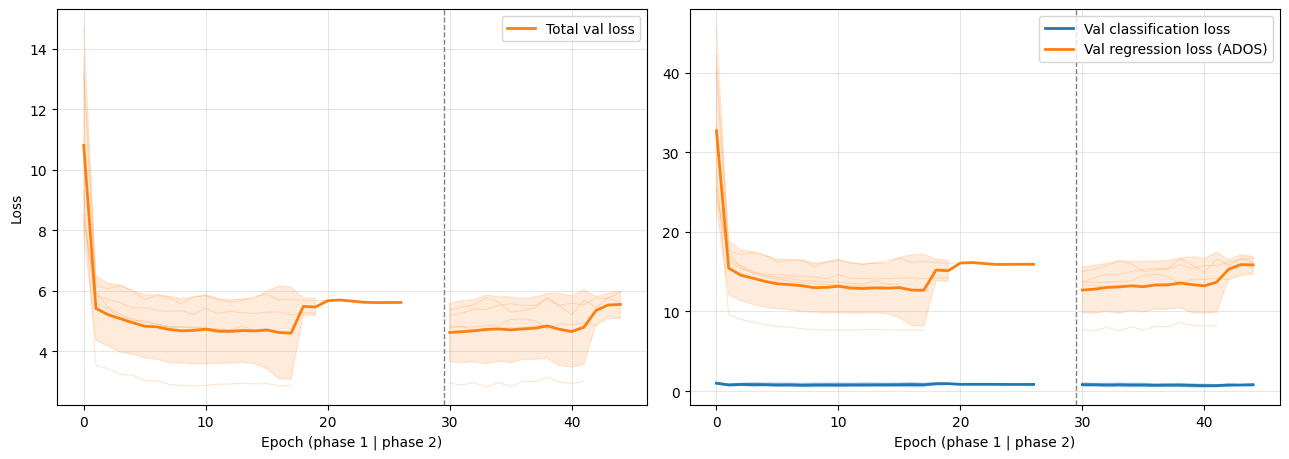

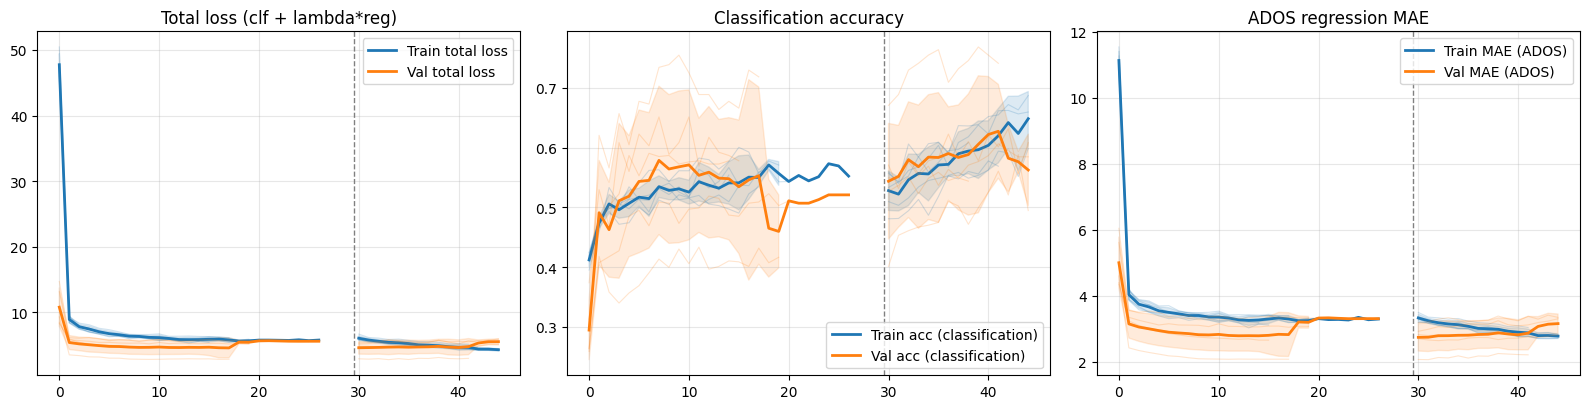

Best epoch (minimum total val_loss, epochs really run) per fold: [22, 21, 38, 15, 13] -> mean ± std = 21.8 ± 9.8


In [ ]:
_ks = sorted(cv_results)

def stack_hist(key):
    hs = [cv_results[k]['history'][key] for k in _ks if key in cv_results[k]['history']]
    L = max(len(h) for h in hs)
    A = np.full((len(hs), L), np.nan)
    for i, h in enumerate(hs):
        A[i, :len(h)] = h
    return A

def plot_band(ax, key, label, color):
    A = stack_hist(key)
    for row in A:
        ax.plot(row, color=color, alpha=0.2, lw=0.8)
    mean, std = np.nanmean(A, axis=0), np.nanstd(A, axis=0, ddof=STD_DDOF)
    x = np.arange(len(mean))
    ax.plot(x, mean, color=color, lw=2, label=label)
    ax.fill_between(x, mean - std, mean + std, color=color, alpha=0.15)

def phase_line(ax):
    ax.axvline(PHASE1_EPOCHS - 0.5, color='gray', ls='--', lw=1)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.7))
plot_band(axes[0], 'val_loss', 'Total val loss', 'tab:orange'); phase_line(axes[0])
axes[0].set_xlabel("Epoch (phase 1 | phase 2)"); axes[0].set_ylabel("Loss"); axes[0].legend(); axes[0].grid(alpha=0.3)
plot_band(axes[1], 'val_class_output_loss', 'Val classification loss', 'tab:blue')
plot_band(axes[1], 'val_reg_output_loss', 'Val regression loss (ADOS)', 'tab:orange'); phase_line(axes[1])
axes[1].set_xlabel("Epoch (phase 1 | phase 2)"); axes[1].legend(); axes[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
plot_band(axes[0], 'loss', 'Train total loss', 'tab:blue')
plot_band(axes[0], 'val_loss', 'Val total loss', 'tab:orange'); phase_line(axes[0])
axes[0].set_title("Total loss (clf + lambda*reg)"); axes[0].legend(); axes[0].grid(alpha=0.3)
plot_band(axes[1], 'class_output_accuracy', 'Train acc (classification)', 'tab:blue')
plot_band(axes[1], 'val_class_output_accuracy', 'Val acc (classification)', 'tab:orange'); phase_line(axes[1])
axes[1].set_title("Classification accuracy"); axes[1].legend(); axes[1].grid(alpha=0.3)
plot_band(axes[2], 'reg_output_mae', 'Train MAE (ADOS)', 'tab:blue')
plot_band(axes[2], 'val_reg_output_mae', 'Val MAE (ADOS)', 'tab:orange'); phase_line(axes[2])
axes[2].set_title("ADOS regression MAE"); axes[2].legend(); axes[2].grid(alpha=0.3)
plt.tight_layout(); plt.show()

_best = np.array([cv_results[k]['metrics']['Best epoch (min val_loss)'] for k in _ks])
print(f"Best epoch (minimum total val_loss, epochs really run) per fold: {_best.tolist()} "
      f"-> mean ± std = {_best.mean():.1f} ± {_best.std(ddof=STD_DDOF):.1f}")

## 10. Final evaluation

Per-fold metrics (seed = 42, 5-fold participant-level CV):


,Precision (%),Recall (%),F1 (%),Accuracy (%),AUC,"MAE (ADOS, session)","MSE (ADOS, session)","RMSE (ADOS, session)","R2 (ADOS, session)","MAE (ADOS, participant)","MSE (ADOS, participant)","RMSE (ADOS, participant)","R2 (ADOS, participant)",Best epoch (min val_loss)
Fold 1,59.524,63.333,57.516,61.538,0.633,2.964,12.577,3.546,-0.008,2.995,12.249,3.500,0.050,22
Fold 2,40.000,40.000,40.000,66.667,0.500,3.548,19.259,4.389,-0.566,3.269,15.900,3.987,-0.250,21
Fold 3,37.500,30.000,33.333,50.000,0.350,2.672,12.168,3.488,-0.271,2.259,9.433,3.071,-0.078,38
Fold 4,66.667,66.667,50.000,50.000,0.519,3.408,15.182,3.896,-0.313,3.518,14.926,3.863,-0.146,15
Fold 5,100.000,100.000,100.000,100.000,1.000,3.568,16.208,4.026,-0.020,3.664,15.909,3.989,0.009,13



VGG16 — mean ± std over 5 folds (std ddof=1):


,Metric,Mean,Std,Mean ± Std
0,Precision (%),60.738095,25.239836,60.738 ± 25.240
1,Recall (%),60.000000,27.182511,60.000 ± 27.183
2,F1 (%),56.169935,26.191280,56.170 ± 26.191
3,Accuracy (%),65.641026,20.540846,65.641 ± 20.541
4,AUC,0.600370,0.245076,0.600 ± 0.245
5,"MAE (ADOS, session)",3.232014,0.396405,3.232 ± 0.396
6,"MSE (ADOS, session)",15.078895,2.893634,15.079 ± 2.894
7,"RMSE (ADOS, session)",3.869113,0.368882,3.869 ± 0.369
8,"R2 (ADOS, session)",-0.235373,0.231803,-0.235 ± 0.232
9,"MAE (ADOS, participant)",3.140946,0.554988,3.141 ± 0.555


  Precision (%)               : 60.738 ± 25.240
  Recall (%)                  : 60.000 ± 27.183
  F1 (%)                      : 56.170 ± 26.191
  Accuracy (%)                : 65.641 ± 20.541
  AUC                         : 0.600 ± 0.245
  MAE (ADOS, session)         : 3.232 ± 0.396
  MSE (ADOS, session)         : 15.079 ± 2.894
  RMSE (ADOS, session)        : 3.869 ± 0.369
  R2 (ADOS, session)          : -0.235 ± 0.232
  MAE (ADOS, participant)     : 3.141 ± 0.555
  MSE (ADOS, participant)     : 13.683 ± 2.808
  RMSE (ADOS, participant)    : 3.682 ± 0.396
  R2 (ADOS, participant)      : -0.083 ± 0.121
  Best epoch (min val_loss)   : 21.800 ± 9.834


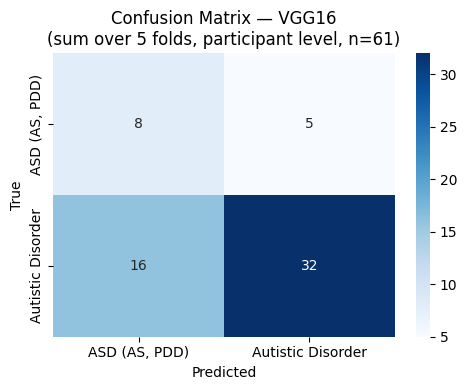

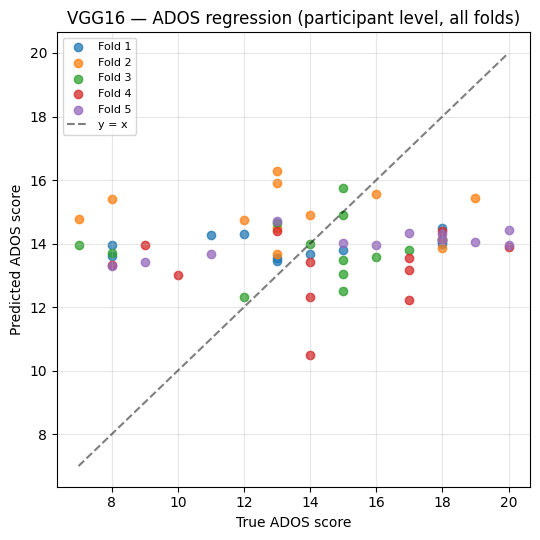

(pooled out-of-fold R2 = -0.043 — indicative only; the reported score is the mean ± std of the per-fold R2 above)

Number of parameters of the VGG16 multi-task model: 14,846,787


In [ ]:
_ks = sorted(cv_results)
assert len(_ks) == N_FOLDS, f"Only {len(_ks)}/{N_FOLDS} folds finished: rerun the CV cell."

per_fold_df = pd.DataFrame([cv_results[k]['metrics'] for k in _ks], index=[f"Fold {k}" for k in _ks])

print(f"Per-fold metrics (seed = {SEED}, {N_FOLDS}-fold participant-level CV):")
display(per_fold_df.round(3))

summary_vgg = pd.DataFrame({
    'Metric': per_fold_df.columns,
    'Mean': per_fold_df.mean().values,
    'Std':  per_fold_df.std(ddof=STD_DDOF).values,
})
summary_vgg['Mean ± Std'] = [f"{m:.3f} ± {s:.3f}" for m, s in zip(summary_vgg['Mean'], summary_vgg['Std'])]

print(f"\nVGG16 — mean ± std over {N_FOLDS} folds (std ddof={STD_DDOF}):")
display(summary_vgg)
for _, r in summary_vgg.iterrows():
    print(f"  {r['Metric']:<28}: {r['Mean ± Std']}")

#Confusion matrix summed over folds 
cm_sum = sum(cv_results[k]['cm'] for k in _ks)
n_part_cv = int(sum(cv_results[k]['n_participants'] for k in _ks))
plt.figure(figsize=(5, 4))
sns.heatmap(cm_sum, annot=True, fmt="d", xticklabels=le.classes_, yticklabels=le.classes_, cmap="Blues")
plt.xlabel("Predicted"); plt.ylabel("True")
plt.title(f"Confusion Matrix — VGG16\n(sum over {N_FOLDS} folds, participant level, n={n_part_cv})")
plt.tight_layout(); plt.show()

# ADOS regression: pooled out-of-fold predictions (participant level)
plt.figure(figsize=(5.5, 5.5))
_cmap = plt.get_cmap('tab10')
for i, k in enumerate(_ks):
    plt.scatter(cv_results[k]['y_ados_true_p'], cv_results[k]['y_ados_pred_p'],
                alpha=0.75, color=_cmap(i), label=f"Fold {k}")
_yt = np.concatenate([cv_results[k]['y_ados_true_p'] for k in _ks])
_yp = np.concatenate([cv_results[k]['y_ados_pred_p'] for k in _ks])
lims = [min(_yt.min(), _yp.min()), max(_yt.max(), _yp.max())]
plt.plot(lims, lims, 'k--', alpha=0.5, label='y = x')
plt.xlabel("True ADOS score"); plt.ylabel("Predicted ADOS score")
plt.title("VGG16 — ADOS regression (participant level, all folds)")
plt.legend(fontsize=8); plt.grid(alpha=0.3)
plt.tight_layout(); plt.show()
print(f"(pooled out-of-fold R2 = {r2_score(_yt, _yp):.3f} — indicative only; "
      f"the reported score is the mean ± std of the per-fold R2 above)")

print(f"\nNumber of parameters of the VGG16 multi-task model: {cv_results[_ks[0]]['n_params']:,}")